<a href="https://colab.research.google.com/github/arif18-tech/TinyML/blob/main/TinyML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

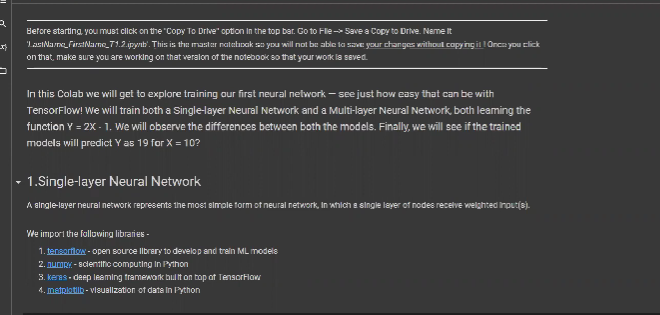

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt

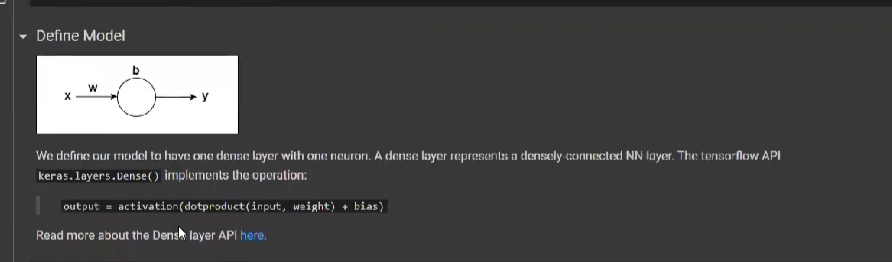

In [ ]:
my_layer = keras.layers.Dense(units=1, input_shape=[1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


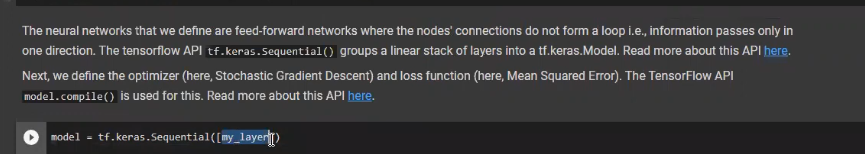

In [ ]:
model=tf.keras.Sequential([my_layer])
model.compile(optimizer='sgd', loss='mean_squared_error')

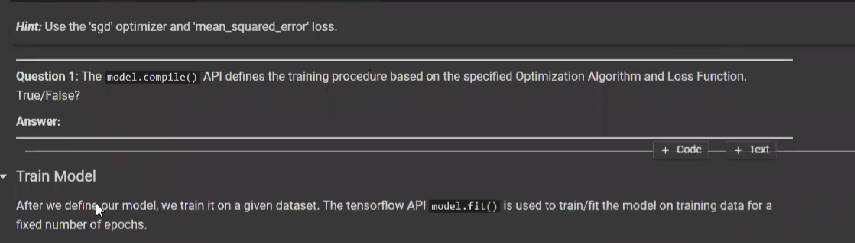

In [ ]:
xs=np.array([-1.0, 0.0, 1.0, 2.0, 3.0, 4.0], dtype=float)
ys=np.array([-3.0, -1.0, 1.0, 3.0, 5.0, 7.0], dtype=float)
model.fit(xs, ys, epoches=500)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - loss: 15.8390
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 12.7061
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 10.2363
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 8.2883
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - loss: 6.7508
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 5.5365
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 4.5765
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 3.8166
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 3.2144
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 2.7363
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.3558
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 2.0523
Epoch 13/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 1.8095
Epoch 14/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.6144
Epoch 15/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.4570
Epoch 16/500
1/

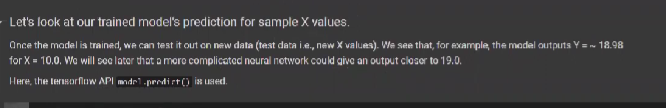

In [12]:
print(model.predict(np.array([9.0])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
[[16.984148]]


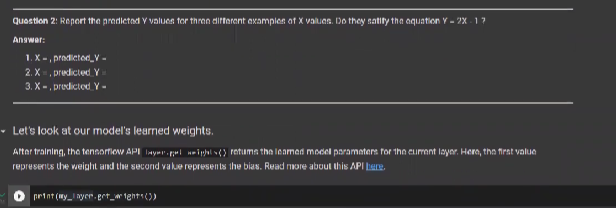

In [13]:
print(my_layer.get_weights())

[array([[1.9973131]], dtype=float32), array([-0.99167], dtype=float32)]


# কোডটা খুব সহজ ভাষায়

এই কোড কম্পিউটারকে একটা সম্পর্ক শিখিয়ে দেয়। তোমার আগের `w*x + b` উদাহরণের সাথে এর সরাসরি মিল আছে।

## আগে ডেটাটা দেখো

| x | -1 | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|---|
| y | -3 | -1 | 1 | 3 | 5 | 7 |

একটু ভাবলে দেখবে: **y = 2x − 1**। যেমন x = 3 হলে 2×3 − 1 = 5। কিন্তু কম্পিউটারকে এই নিয়মটা বলা হয়নি। সে শুধু x আর y এর জোড়া দেখে নিজে নিজে নিয়মটা খুঁজে বের করবে। অর্থাৎ তাকে `w = 2` আর `b = -1` খুঁজে বের করতে হবে।

## লাইন ১: layer বানানো

```python
my_layer = keras.layers.Dense(units=1, input_shape=[1])
```

- `Dense` = একটা নিউরন বানাও, যেটা `w*x + b` হিসাব করে।
- `units=1` = ১টা নিউরন লাগবে।
- `input_shape=[1]` = ইনপুট হিসেবে ১টা সংখ্যা (x) ঢুকবে।

এই নিউরনে একটা `w` আর একটা `b` থাকে, যা শুরুতে এলোমেলো মান নিয়ে থাকে।

## লাইন ২: model বানানো

```python
model = tf.keras.Sequential([my_layer])
```

`Sequential` মানে layer গুলো লাইন ধরে সাজানো। এখানে মাত্র একটাই layer, তাই model মানে ওই একটা নিউরনই।

## লাইন ৩: কীভাবে শিখবে তা ঠিক করা

```python
model.compile(optimizer='sgd', loss='mean_squared_error')
```

শেখার আগে দুটো জিনিস ঠিক করতে হয়:

- **`loss='mean_squared_error'`** হলো ভুল মাপার নিয়ম। মডেল যা অনুমান করল আর আসল উত্তরের মধ্যে ফারাক কতটা, সেটা বর্গ করে গড় করা হয়। ফারাক যত বেশি, loss তত বড়।
- **`optimizer='sgd'`** হলো ভুল কমানোর কৌশল। loss দেখে সে `w` আর `b` কে অল্প অল্প করে এমনভাবে বদলায়, যাতে পরের বার ভুল কম হয়।

একটা উপমা: অন্ধকার ঘরে দেয়াল হাতড়ে হাতড়ে দরজা খোঁজা। loss বলে "দরজা থেকে কতটা দূরে আছো", আর optimizer বলে "একটু ডানে সরো"।

## লাইন ৪ ও ৫: ডেটা দেওয়া

```python
xs = np.array([-1.0, 0.0, 1.0, 2.0, 3.0, 4.0], dtype=float)
ys = np.array([-3.0, -1.0, 1.0, 3.0, 5.0, 7.0], dtype=float)
```

`xs` হলো প্রশ্ন (ইনপুট), `ys` হলো সঠিক উত্তর। `np.array` দিয়ে সাধারণ লিস্টকে NumPy array বানানো হয়েছে, কারণ TensorFlow এই আকারেই ডেটা নেয়।

## লাইন ৬: আসল শেখা (training)

```python
model.fit(xs, ys, epochs=500)
```

> ⚠️ তোমার কোডে বানান ভুল আছে: `epoches` নয়, সঠিক হলো **`epochs`**। ভুল বানানে error আসবে।

`fit` মানে "ডেটা দেখে শেখো"। **epoch** মানে সব ডেটা একবার করে দেখা। `epochs=500` মানে এই কাজ ৫০০ বার হবে। প্রতিটা epoch এ চারটা ধাপ চলে:

1. মডেল `w*x + b` দিয়ে অনুমান করে।
2. loss দিয়ে ভুল মাপা হয়।
3. optimizer `w` আর `b` একটু বদলায়।
4. আবার শুরু থেকে।

শুরুতে মডেল ভুল করে। যেমন `w = 0.3`, `b = 0.1`, তাই x = 3 এ সে প্রায় ১ বলে, অথচ উত্তর ৫। ৫০০ বার ঘষামাজা করতে করতে `w` প্রায় 2 আর `b` প্রায় -1 এর কাছে চলে আসে।

## লাইন ৭: পরীক্ষা

```python
print(model.predict(np.array([9.0])))
```

এবার একটা নতুন x = 9 দেওয়া হলো, যেটা ডেটাতে ছিলই না। সঠিক নিয়মে উত্তর হওয়া উচিত 2×9 − 1 = **17**। মডেল পুরো ঠিক 17 দেবে না, দেবে 16.98 এর মতো কিছু, কারণ `w` আর `b` প্রায় ঠিক হয়, হুবহু ঠিক হয় না। এটা স্বাভাবিক।

## এক নজরে

| ধাপ | কাজ |
|---|---|
| `Dense` | `w*x+b` নিউরন বানানো |
| `Sequential` | layer কে model এ সাজানো |
| `compile` | ভুল মাপার নিয়ম (loss) আর ঠিক করার কৌশল (optimizer) বাছা |
| `fit` | ৫০০ বার ঘষে `w`, `b` শেখা |
| `predict` | শেখা নিয়মে নতুন x এর উত্তর বলা |

## তোমার প্রথম প্রশ্নের সাথে মিল

তোমার আগের `Model` class এ আমরা নিজে হাতে `w` আর `b` বানিয়েছিলাম (`tf.Variable`)। এখানে `Dense` সেই কাজটা নিজেই করে দেয়: ভেতরে `w` আর `b` বানায়, আর `fit` সেগুলো ধীরে ধীরে ঠিক করে। দুটোই একই জিনিস, শুধু Keras এখানে অনেক কাজ আগে থেকে করে রেখেছে।

চাইলে `fit` এর ভেতরে `w` আর `b` কীভাবে ৫০০ ধাপে বদলায়, সেটা animation দিয়ে দেখাতে পারি।

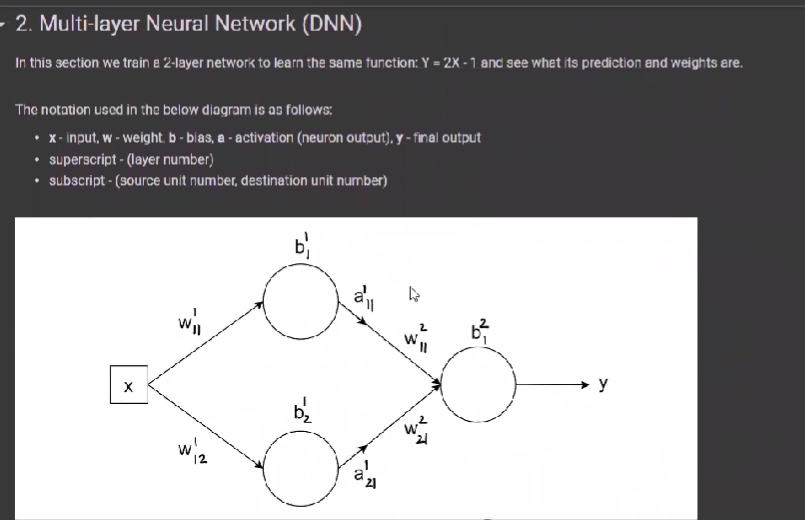

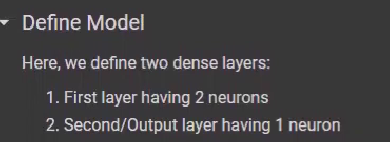

In [15]:
my_layer_1= keras.layers.Dense(units=2, input_shape=[1])
my_layer_2 = keras.layers.Dense(units=1) #donot need to define input shape here, its automatically connected

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model=tf.keras.Sequential([my_layer_1, my_layer_2])
model.compile(optimizer='sgd', loss='mean_squared_error')

In [18]:
xs=np.array([-1.0, 0.0, 1.0, 2.0, 3.0, 4.0], dtype=float)
ys=np.array([-3.0, -1.0, 1.0, 3.0, 5.0, 7.0], dtype=float)
model.fit(xs, ys, epochs=500)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - loss: 23.0182
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 16.1264
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 11.9321
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 8.8369
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 6.4110
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 4.5495
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 3.2138
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.3328
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.7938
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 1.4767
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.2862
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 1.1613
Epoch 13/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 1.0689
Epoch 14/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - loss: 0.9927
Epoch 15/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.9256
Epoch 16/500
1/

In [21]:
print(model.predict(np.array([9.0])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
[[16.999994]]


In [22]:
print(my_layer_1.get_weights())
print(my_layer_2.get_weights())

[array([[-1.1486331 , -0.39875758]], dtype=float32), array([0.4382946, 0.1179169], dtype=float32)]
[array([[-1.6228784 ],
       [-0.34082687]], dtype=float32), array([-0.24851048], dtype=float32)]


In [30]:
value_to_predict = 10.8
#extracting weigh. and Dias values of layer 1
layer1_w1 = (my_layer_1.get_weights()[0][0][0]) #w1_11
layer1_w2 = (my_layer_1.get_weights()[0][0][1]) #w1_12
layer1_b1 = (my_layer_1.get_weights()[1][0]) #b1_1
layer1_b2 = (my_layer_1.get_weights()[1][1]) #b1_2
# extracting weigh. and Dias values of layer 2
layer2_w1 = (my_layer_2.get_weights()[0][0][0]) #w2_11
layer2_w2 = (my_layer_2.get_weights()[0][1][0]) #w2_21
layer2_b = (my_layer_2.get_weights()[1][0]) #b2_1
#artivations
neuron1_output =(layer1_w1 * value_to_predict) + layer1_b1 #a1_11
neuron2_output = (layer1_w2 * value_to_predict) + layer1_b2 #a1 21
#final ourpит
neuron3_output = (layer2_w1* neuron1_output) + (layer2_w2 * neuron2_output) + layer2_b
print("Layer 1 Weights: ", layer1_w1, ", ", layer1_w2)
print("Layer 1 Biases:", layer1_b1, ", ", layer1_b2)
print()
print("Layer 2 Weights: ", layer2_w1, ", ", layer2_w2)
print("Layer 2 Biases:", layer2_b)
print()
print("neuron 1 output:", neuron1_output)
print("neuron 2 output:", neuron2_output)
print()
print("final output:", neuron3_output)

Layer 1 Weights:  -1.1486331 ,  -0.39875758
Layer 1 Biases: 0.4382946 ,  0.1179169

Layer 2 Weights:  -1.6228784 ,  -0.34082687
Layer 2 Biases: -0.24851048

neuron 1 output: -11.966944
neuron 2 output: -4.188665

final output: 20.599995


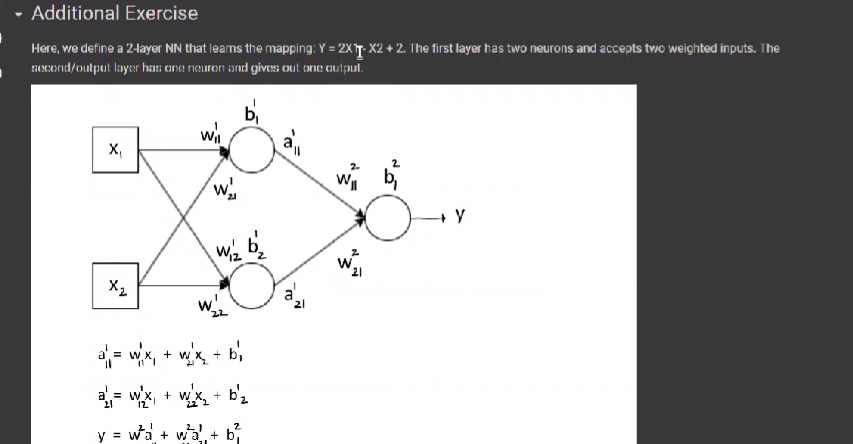

In [37]:
my_layer_1= keras.layers.Dense(units=2, input_shape=(2,))
my_layer_2 = keras.layers.Dense(units=1)

model=tf.keras.Sequential([my_layer_1, my_layer_2])

# define optimizer and loss fun
opt = keras.optimizers.Adam(learning_rate=0.01)
model.compile(optimizer=opt, loss='mean_squared_error')

# creating ground truth data
xs = []
ys = []
for x1 in range(100):
    for x2 in range(100):
        xs.append([x1, x2])
        ys.append([2*x1 - x2 + 2])
xs = np.array(xs)
ys = np.array(ys)

# train model
model.fit(xs, ys, epochs=20)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 5566.5786 
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 7.1721 
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0202
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0163
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0125
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0090
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0060
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0037
Epoch 9/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0021
Epoch 10/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0011
Epoch 11/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 4.8437e-04
Epoch 12/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.8940e-04
Epoch 13/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 6.2810e-05
Epoch 14/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.7338e-05
Epoch 15/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms

In [38]:
print(xs.shape)
print(ys.shape)

(10000, 2)
(10000, 1)


In [39]:
print(model.predict(np.array([[120.0, -10.0]])))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
[[252.]]
